[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Tnecniv-Teikram/NSA-hyperspectral-course-2026/blob/main/21_validation_accuracy_assessment.ipynb)

*Running in Colab? Run the setup cell below first — it clones the course and installs what this notebook needs. Running locally? It does nothing.*

# ✅ Validation & Accuracy Assessment — How Good Is Your Map, Really?
### Space Academy 2026 · Hyperspectral course · Week 3 — Validation methods and accuracy assessment (Lecture + Practical)

"It looks right on the map" is not a validation. Judges, users and reviewers want numbers **with uncertainty**, obtained
from reference data that is **independent** of the training data, and computed in a way that represents the whole
map. This notebook walks through the complete toolbox on a real Tanager land-cover map of Ho Chi Minh City.

**What you will learn**
- The three components of an accuracy assessment: *sampling design*, *response design* and *analysis* (Stehman & Foody 2019)
- Confusion-matrix metrics: overall, user's and producer's accuracy, F1, IoU, macro vs weighted averages —
  and why **kappa** is discouraged (Pontius & Millones 2011), with quantity and allocation disagreement as alternatives
- Why **random cross-validation is optimistic** for maps and how **spatial (block) cross-validation** fixes it
- How to design a **stratified random sample** and compute **area-adjusted accuracy and area estimates with 95 %
  confidence intervals** (Olofsson et al. 2014)
- How to quantify agreement for **continuous products** (RMSE, MAE, bias, R², Bland–Altman) and check
  **cross-date consistency** on stable targets
- What to report in your project to score on the **Validity** criterion

**Prerequisites:** notebook 15 (classification) — notebook 20 (deep learning) is helpful but not required.

**Data**
| Role | Scene ID | Place |
|---|---|---|
| Land-cover map & assessment | `20250407_035509_25_4001` | Ho Chi Minh City, Vietnam |
| Cross-date consistency (optional) | `20241215_185916_33_4001` + `20250123_185518_92_4001` | Malibu / Santa Monica Mountains, USA |

Reference labels: **ESA WorldCover 2021** aggregated to 30 m (`data/labels/`). `hu.get_scene()` finds the local HDF5 or
downloads it (~1 GB) from Planet's open STAC catalogue.

In [ ]:
# --- Setup: works both in Google Colab and in a local environment --------------------
# In Colab this clones the course repository, installs the geospatial packages that Colab
# does not ship, and moves into the course folder so the notebook finds hsi_utils and data/.
# Locally it does nothing at all — your own environment is already active.
import os
import pathlib
import subprocess
import sys

REPO = "Tnecniv-Teikram/NSA-hyperspectral-course-2026"          # change with: python tools/set_repo_url.py <owner>/<repo>

if "google.colab" in sys.modules:
    course = pathlib.Path("/content/hyperspectral-course")
    if not course.exists():
        subprocess.run(["git", "clone", "--depth", "1", "-q",
                        f"https://github.com/{REPO}.git", str(course)], check=True)
    os.chdir(course)
    sys.path.insert(0, str(course))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "h5py", "rasterio", "rioxarray", "xarray", "geopandas"], check=True)
    print("Colab ready — course at", course)
else:
    print("Local environment:", sys.executable.split("/")[-3])


In [1]:
# On Google Colab: upload hsi_utils.py next to this notebook and uncomment:
# %pip install -q h5py numpy scipy matplotlib scikit-learn pandas rasterio xarray rioxarray requests
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, cohen_kappa_score, confusion_matrix, f1_score
from sklearn.model_selection import GroupKFold, KFold

import hsi_utils as hu

plt.rcParams["figure.dpi"] = 90
SEED = 42
rng = np.random.default_rng(SEED)
T_START = time.time()

## 1. Lecture: what does "validation" mean for a map?

A map is a *model* of the world, so every map contains errors. An accuracy assessment estimates **how many errors,
of which kind, and where** — for the map as a whole, not just for the pixels you happened to label. Following
Stehman & Foody (2019), a rigorous assessment has three parts:

| Component | Question | Example in this notebook |
|---|---|---|
| **Sampling design** | *Which* locations do we check? | stratified random sample of map pixels (Section 5) |
| **Response design** | *How* do we decide the true class at a location? | WorldCover majority class in the 30 m pixel (a stand-in for field work or VHR photo-interpretation) |
| **Analysis** | *How* do we turn the sample into estimates? | error matrix → area-weighted accuracy and area estimates with 95 % CIs |

Two golden rules:
1. **Independence.** Reference data used for assessment must not have been used for training, tuning or
   threshold selection — and should not be *spatially adjacent* to training data (spatial autocorrelation).
2. **Probability sampling.** Every map pixel must have a known, non-zero chance of being sampled; otherwise the
   estimate only describes the pixels you chose (for example, only the easy, homogeneous ones).

⚠️ **About our reference data.** Real projects collect reference data in the field or by interpreting very-high-resolution
imagery. For a self-contained notebook we use **ESA WorldCover 2021** as reference. It is itself a map
(≈ 75 % overall accuracy globally), from 2021 not 2025, and at 10 m instead of 30 m. The numbers below therefore
measure **agreement with WorldCover**, not true accuracy — the *methods* are exactly what you would use with real reference data.

## 2. Data and a quick Random Forest map

We classify a 400 × 400 pixel window (12 × 12 km) of southern Ho Chi Minh City into five classes. The window is
cut into 40 × 40 pixel blocks; **half of the blocks** provide training pixels, the other half are kept for assessment.

**Legend harmonisation.** The map legend must match the reference legend. WorldCover has more classes than we map,
so we merge them: shrubland and herbaceous wetland → grassland, bare/sparse vegetation → built-up & bare, mangroves → tree cover.
Always document such decisions.

In [2]:
SCENE_ID = "20250407_035509_25_4001"
WINDOW = (150, 550, 150, 550)
CLASSES = [10, 30, 40, 50, 80]
NAMES = ["Tree cover", "Grassland", "Cropland", "Built-up & bare", "Water"]
COLORS = [hu.WORLDCOVER_CLASSES[c][1] for c in CLASSES]
K = len(CLASSES)
HARMONISE = {20: 30, 90: 30, 100: 30, 60: 50, 95: 10}      # WorldCover code → map legend code

scene = hu.get_scene(SCENE_ID)
cube, wl = scene.read_cube(WINDOW)
wc, purity = hu.load_labels(SCENE_ID, WINDOW)
B, H, W = cube.shape
valid = np.all(np.isfinite(cube), axis=0)

wc_h = wc.copy()
for src, dst in HARMONISE.items():
    wc_h[wc == src] = dst
ref_idx = np.full((H, W), -1)                  # reference class index 0..K-1 (-1 = no reference)
for k, code in enumerate(CLASSES):
    ref_idx[wc_h == code] = k
ref_idx[~valid] = -1

BLOCK = 40
blocks = (np.arange(H) // BLOCK)[:, None] * (W // BLOCK) + (np.arange(W) // BLOCK)[None, :]
train_blocks = rng.permutation(blocks.max() + 1)[: (blocks.max() + 1) // 2]
is_train_area = np.isin(blocks, train_blocks)
print(f"window {H}×{W}, {valid.mean() * 100:.1f}% valid; training area = {is_train_area.mean() * 100:.0f}% of the window")

window 400×400, 98.1% valid; training area = 50% of the window


In [3]:
# Training sample: up to 600 PURE pixels per class from the training blocks
pure = (purity == 9) & (ref_idx >= 0)
tr_rows, tr_cols = [], []
for k in range(K):
    r, c = np.nonzero(pure & is_train_area & (ref_idx == k))
    pick = rng.choice(len(r), size=min(600, len(r)), replace=False)
    tr_rows.append(r[pick]); tr_cols.append(c[pick])
tr_rows, tr_cols = np.concatenate(tr_rows), np.concatenate(tr_cols)

# Features: 30 principal components of the 352 good bands (fast and almost lossless, see notebook 13)
pca = PCA(30, random_state=SEED).fit(cube[:, tr_rows, tr_cols].T)
pix, ok = hu.cube_to_pixels(cube)
features = hu.pixels_to_image(pca.transform(pix), ok)          # (30, H, W)
F_all = features.reshape(30, -1).T                              # (H*W, 30)

X_train = features[:, tr_rows, tr_cols].T
y_train = ref_idx[tr_rows, tr_cols]
rf = RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample", n_jobs=4, random_state=SEED)
rf.fit(X_train, y_train)

map_idx = np.full(H * W, -1)
map_idx[ok.ravel()] = rf.predict(F_all[ok.ravel()])
map_idx = map_idx.reshape(H, W)
print("training pixels per class:", np.bincount(y_train))

training pixels per class: [600 600 600 600 600]


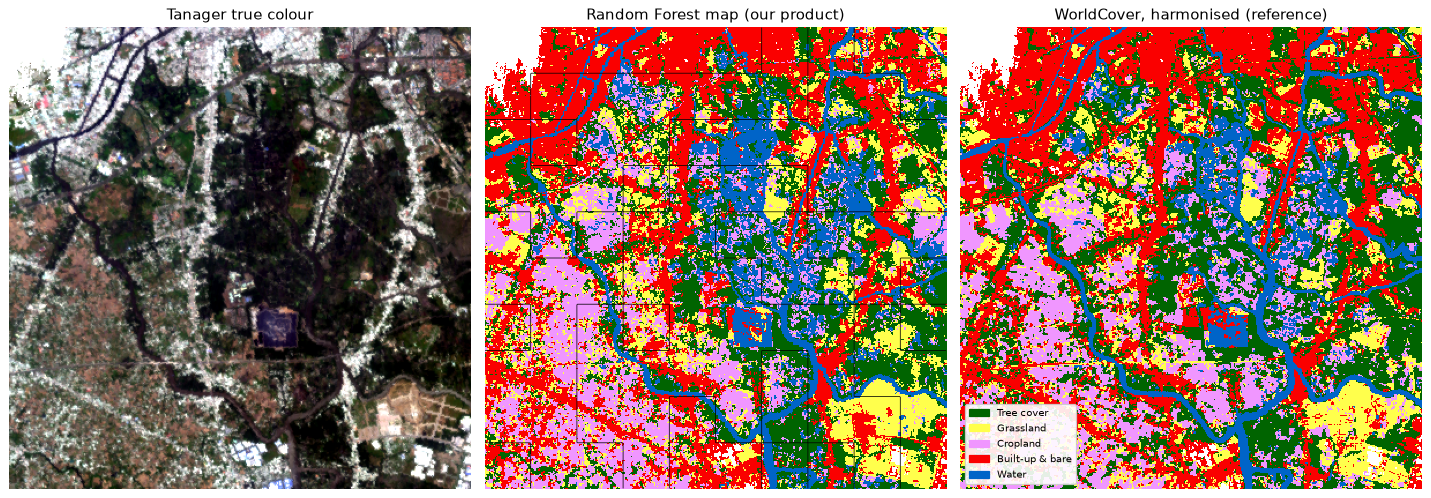

Black outlines in the middle panel: training blocks (never used for assessment).


In [4]:
cmap = ListedColormap(COLORS)
legend = [Patch(color=c, label=n) for c, n in zip(COLORS, NAMES)]

def show(ax, idx, title):
    ax.imshow(np.ma.masked_less(idx, 0), cmap=cmap, vmin=-0.5, vmax=K - 0.5, interpolation="nearest")
    ax.set_title(title); ax.axis("off")

fig, axes = plt.subplots(1, 3, figsize=(16, 5.6))
axes[0].imshow(hu.rgb_from_cube(cube, wl)); axes[0].set_title("Tanager true colour"); axes[0].axis("off")
show(axes[1], map_idx, "Random Forest map (our product)")
show(axes[2], ref_idx, "WorldCover, harmonised (reference)")
axes[2].legend(handles=legend, loc="lower left", fontsize=8, framealpha=0.9)
axes[1].contour(is_train_area, levels=[0.5], colors="k", linewidths=0.6)
plt.tight_layout(); plt.show()
print("Black outlines in the middle panel: training blocks (never used for assessment).")

## 3. The confusion (error) matrix and its metrics

We first use the classic approach: a **test set** of pure reference pixels from the assessment blocks.

**Orientation convention.** In remote sensing the error matrix usually has **rows = map (predicted) class** and
**columns = reference class** (Congalton; Olofsson et al. 2014). scikit-learn's `confusion_matrix(y_true, y_pred)` uses
the opposite, so we transpose it. Always state your orientation in a report.

| Metric | Formula (rows = map *i*, columns = reference *j*) | Question it answers |
|---|---|---|
| Overall accuracy (OA) | $\sum_i n_{ii} / n$ | What fraction of pixels is correct? |
| User's accuracy (UA) — *precision* | $n_{ii} / n_{i+}$ | If the map says "water", how often is it water? (commission error = 1 − UA) |
| Producer's accuracy (PA) — *recall* | $n_{jj} / n_{+j}$ | How much of the real water did the map find? (omission error = 1 − PA) |
| F1 | $2\,UA\,PA / (UA + PA)$ | Balance of both errors for one class |
| IoU (Jaccard) | $n_{ii} / (n_{i+} + n_{+i} - n_{ii})$ | Overlap of mapped and reference class — standard for segmentation |
| Macro average | mean over classes | every class counts equally (good for rare classes) |
| Weighted average | mean weighted by class frequency | dominated by common classes |

In [5]:
test_mask = pure & ~is_train_area & (map_idx >= 0)
te_rows, te_cols = np.nonzero(test_mask)
y_ref, y_map = ref_idx[te_rows, te_cols], map_idx[te_rows, te_cols]

cm = confusion_matrix(y_ref, y_map, labels=range(K)).T          # rows = map, columns = reference
n = cm.sum()
diag = np.diag(cm)
UA = diag / cm.sum(1)
PA = diag / cm.sum(0)
F1 = 2 * UA * PA / (UA + PA)
IoU = diag / (cm.sum(1) + cm.sum(0) - diag)
OA = diag.sum() / n

em = pd.DataFrame(cm, index=[f"map: {x}" for x in NAMES], columns=[f"ref: {x}" for x in NAMES])
em["row total"] = cm.sum(1)
em.loc["column total"] = list(cm.sum(0)) + [n]
display(em)

metrics = pd.DataFrame({"UA (precision)": UA, "PA (recall)": PA, "F1": F1, "IoU": IoU,
                        "reference pixels": cm.sum(0)}, index=NAMES)
display(metrics.round(3))
print(f"Overall accuracy          {OA:.3f}")
print(f"Macro F1 / weighted F1    {F1.mean():.3f} / {np.average(F1, weights=cm.sum(0)):.3f}")
print(f"sklearn check             OA {accuracy_score(y_ref, y_map):.3f}, macro F1 {f1_score(y_ref, y_map, average='macro'):.3f}")

,ref: Tree cover,ref: Grassland,ref: Cropland,ref: Built-up & bare,ref: Water,row total
map: Tree cover,10175,501,916,440,256,12288
map: Grassland,1334,3078,1054,481,105,6052
map: Cropland,1913,580,4548,277,380,7698
map: Built-up & bare,641,495,116,11924,107,13283
map: Water,546,30,559,116,5187,6438
column total,14609,4684,7193,13238,6035,45759


,UA (precision),PA (recall),F1,IoU,reference pixels
Tree cover,0.828,0.696,0.757,0.608,14609
Grassland,0.509,0.657,0.573,0.402,4684
Cropland,0.591,0.632,0.611,0.440,7193
Built-up & bare,0.898,0.901,0.899,0.817,13238
Water,0.806,0.859,0.832,0.712,6035


Overall accuracy          0.763
Macro F1 / weighted F1    0.734 / 0.766
sklearn check             OA 0.763, macro F1 0.734


### Kappa — and why you should not rely on it

Cohen's kappa $\kappa = (p_o - p_e)/(1 - p_e)$ "corrects" OA for the agreement $p_e$ expected by chance from the
row and column totals. It is still widely reported, but Pontius & Millones (2011) and Foody (2020) show that the
chance baseline is not meaningful for maps, that kappa is highly correlated with OA, and that it does not tell you
*what kind* of error you made. They recommend reporting the error matrix together with two complementary numbers:

- **Quantity disagreement** $Q = \tfrac12\sum_g |p_{g+} - p_{+g}|$ — the map has the wrong *amount* of a class;
- **Allocation disagreement** $A = \tfrac12\sum_g 2\min(p_{g+} - p_{gg},\; p_{+g} - p_{gg})$ — right amount, wrong *place*.

Together they add up to the total disagreement: $Q + A = 1 - OA$.

In [6]:
p = cm / n
p_row, p_col = p.sum(1), p.sum(0)
Q = 0.5 * np.abs(p_row - p_col).sum()
A = 0.5 * (2 * np.minimum(p_row - np.diag(p), p_col - np.diag(p))).sum()
kappa = cohen_kappa_score(y_ref, y_map)
print(f"kappa = {kappa:.3f}")
print(f"quantity disagreement Q = {Q:.3f}, allocation disagreement A = {A:.3f}, Q + A = {Q + A:.3f} = 1 − OA = {1 - OA:.3f}")
per_class_q = pd.Series(p_row - p_col, index=NAMES)
print("\nMap minus reference proportion per class (+ = over-mapped):")
print(per_class_q.round(3).to_string())

kappa = 0.693
quantity disagreement Q = 0.051, allocation disagreement A = 0.186, Q + A = 0.237 = 1 − OA = 0.237

Map minus reference proportion per class (+ = over-mapped):
Tree cover        -0.051
Grassland          0.030
Cropland           0.011
Built-up & bare    0.001
Water              0.009


⚠️ **The test set above is biased in two ways.** It contains only *pure* pixels (the easy ones — mixed pixels at
class boundaries are excluded), and its class proportions follow WorldCover, not the map. Section 5 fixes both with a
proper probability sample. First, let us look at the other big source of optimism: **spatial autocorrelation**.

## 4. Random vs spatial cross-validation

Cross-validation (CV) is used to tune and compare models *before* the final assessment. With **random** K-fold CV,
each test pixel usually has training pixels a few metres away that look almost identical, so CV measures
*interpolation* skill. A map is used to predict *new places*, so we need **spatial CV**: split by blocks, so that
test folds are spatially separated from the training folds (Roberts et al. 2017; Ploton et al. 2020; Meyer & Pebesma 2022).

How large should blocks be? At least as large as the range of **spatial autocorrelation** of the data. The
correlogram below shows how the correlation between pixels decays with distance.

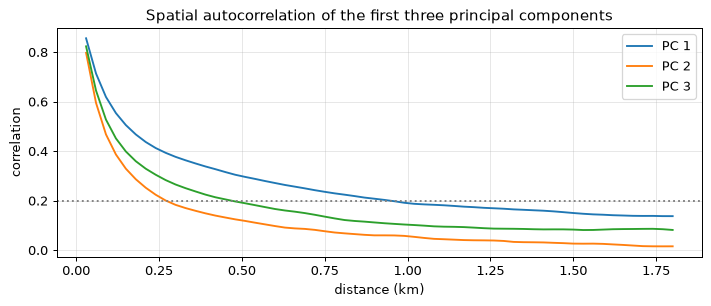

In [7]:
def correlogram(img, max_lag=60):
    # Pearson correlation between pixels separated by `lag` pixels (horizontal and vertical pairs)
    lags, r = np.arange(1, max_lag + 1), []
    for lag in lags:
        a = np.concatenate([img[:, :-lag].ravel(), img[:-lag, :].ravel()])
        b = np.concatenate([img[:, lag:].ravel(), img[lag:, :].ravel()])
        good = np.isfinite(a) & np.isfinite(b)
        r.append(np.corrcoef(a[good], b[good])[0, 1])
    return lags, np.array(r)

fig, ax = plt.subplots(figsize=(8, 3.5))
for i in range(3):
    lags, r = correlogram(features[i])
    ax.plot(lags * 30 / 1000, r, label=f"PC {i + 1}")
ax.axhline(0.2, color="grey", ls=":")
ax.set(xlabel="distance (km)", ylabel="correlation", title="Spatial autocorrelation of the first three principal components")
ax.grid(alpha=0.3); ax.legend(); plt.tight_layout(); plt.show()

In [8]:
# Labelled sample for CV: 8000 pure pixels from the whole window
cv_pool = np.flatnonzero((pure & ok).ravel())
cv_idx = rng.choice(cv_pool, size=min(8000, len(cv_pool)), replace=False)
Xcv, ycv = F_all[cv_idx], ref_idx.ravel()[cv_idx]
cv_rows, cv_cols = np.unravel_index(cv_idx, (H, W))

def cv_accuracy(splitter, groups=None):
    scores = []
    for tr, te in splitter.split(Xcv, ycv, groups):
        m = RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample", n_jobs=4, random_state=SEED)
        scores.append(accuracy_score(ycv[te], m.fit(Xcv[tr], ycv[tr]).predict(Xcv[te])))
    return np.mean(scores), np.std(scores)

t = time.time()
random_cv = cv_accuracy(KFold(5, shuffle=True, random_state=SEED))
block_sizes = [3, 6, 12, 25, 50, 100]
spatial_cv = {}
for bs in block_sizes:
    groups = (cv_rows // bs) * (W // bs + 1) + cv_cols // bs
    spatial_cv[bs] = cv_accuracy(GroupKFold(5), groups)
print(f"cross-validation done in {time.time() - t:.0f} s")
print(f"random 5-fold CV       OA = {random_cv[0]:.3f} ± {random_cv[1]:.3f}")
for bs, (m, s) in spatial_cv.items():
    print(f"spatial CV, {bs:3d}-px blocks ({bs * 30 / 1000:4.2f} km)  OA = {m:.3f} ± {s:.3f}")

cross-validation done in 17 s
random 5-fold CV       OA = 0.812 ± 0.011
spatial CV,   3-px blocks (0.09 km)  OA = 0.805 ± 0.008
spatial CV,   6-px blocks (0.18 km)  OA = 0.801 ± 0.009
spatial CV,  12-px blocks (0.36 km)  OA = 0.799 ± 0.015
spatial CV,  25-px blocks (0.75 km)  OA = 0.786 ± 0.027
spatial CV,  50-px blocks (1.50 km)  OA = 0.776 ± 0.026
spatial CV, 100-px blocks (3.00 km)  OA = 0.764 ± 0.042


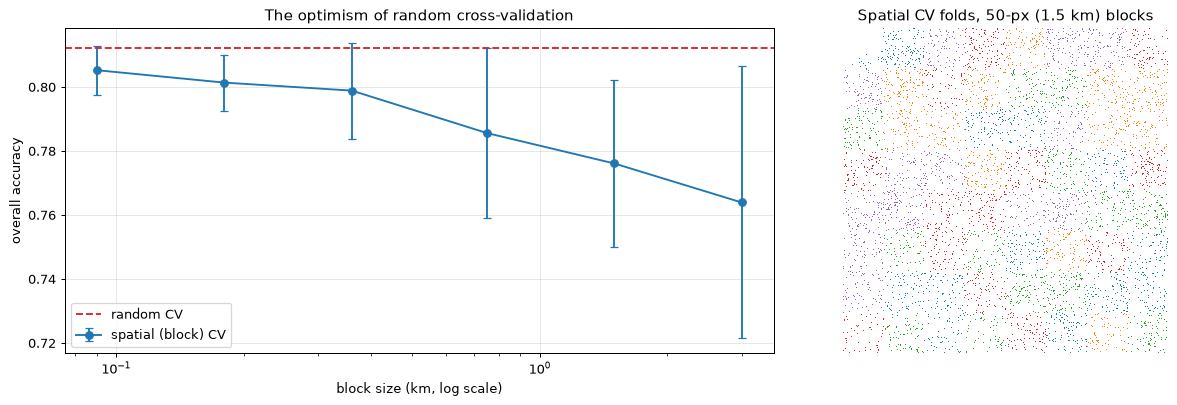

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
km = np.array(block_sizes) * 30 / 1000
ax.errorbar(km, [spatial_cv[b][0] for b in block_sizes], yerr=[spatial_cv[b][1] for b in block_sizes],
            marker="o", capsize=3, label="spatial (block) CV")
ax.axhline(random_cv[0], color="C3", ls="--", label="random CV")
ax.set_xscale("log"); ax.set(xlabel="block size (km, log scale)", ylabel="overall accuracy",
                             title="The optimism of random cross-validation")
ax.grid(alpha=0.3); ax.legend()

bs = 50
groups = (cv_rows // bs) * (W // bs + 1) + cv_cols // bs
fold = np.full((H, W), np.nan)
for f, (_, te) in enumerate(GroupKFold(5).split(Xcv, ycv, groups)):
    fold[cv_rows[te], cv_cols[te]] = f
axes[1].imshow(fold, cmap="tab10", vmin=0, vmax=9, interpolation="nearest")
axes[1].set_title(f"Spatial CV folds, {bs}-px (1.5 km) blocks"); axes[1].axis("off")
plt.tight_layout(); plt.show()

**Interpretation.** Random CV reports the highest accuracy. As blocks grow, test pixels move away from training
pixels and the accuracy falls towards what you can expect in *new* areas. Once the blocks are larger than the
autocorrelation range, the estimate stabilises (with more fold-to-fold variation, because each fold now contains
different landscapes). Report spatial CV, state the block size, and ideally choose it from the correlogram.

Tools for real projects: `GroupKFold` / `StratifiedGroupKFold` in scikit-learn with block IDs, or packages such as
*blockCV* (R) and *spacv* / *verde* (Python). For patch-based models also add a **buffer** between folds (notebook 20).

## 5. Design-based accuracy and area estimation (Olofsson et al. 2014)

> **Core versus reference.** Sections 1–4 are the part every project must get right: the error matrix, overall
> accuracy, user's and producer's accuracy, and a spatially independent split. If you take nothing else from this
> notebook, take those.
>
> This section — design-based area estimation with confidence intervals — is **graduate-level survey statistics**
> and is included as a working reference. The idea you must absorb is short: *counting map pixels is a biased way
> to measure area, because the map has errors; a stratified reference sample lets you correct the estimate and put
> an honest confidence interval on it.* Use the code as a template when a project needs defensible area figures.


The **map is used to report areas** ("how many hectares of cropland?"). Pixel counting gives an area, but it is biased
by the map errors. The good-practice recipe of Olofsson et al. (2014) estimates accuracy **and** error-adjusted areas,
with confidence intervals, from a **stratified random sample**.

**Population:** all valid map pixels in the *assessment* blocks (training blocks are excluded — their labels were used
for training). **Strata:** the map classes.

### 5.1 How many samples?

For stratified random sampling, the sample size needed to estimate OA with a target standard error $S(\hat O)$ is
(Olofsson et al. 2014, Eq. 13; Cochran 1977)

$$ n = \left(\frac{\sum_i W_i S_i}{S(\hat O)}\right)^2, \qquad S_i = \sqrt{U_i (1 - U_i)} $$

where $W_i$ is the mapped area proportion of class $i$ and $U_i$ a *conjectured* user's accuracy (a guess, e.g. from a pilot).

In [10]:
population = (map_idx >= 0) & ~is_train_area
N_i = np.array([np.sum(population & (map_idx == k)) for k in range(K)])     # map pixels per stratum
W_i = N_i / N_i.sum()
PIXEL_HA = 30 * 30 / 1e4                                                       # 0.09 ha per pixel

U_guess = np.array([0.80, 0.60, 0.70, 0.85, 0.95])                            # conjectured user's accuracies
TARGET_SE = 0.015
n_total = int(np.ceil((np.sum(W_i * np.sqrt(U_guess * (1 - U_guess))) / TARGET_SE) ** 2))

MIN_PER_CLASS = 50
n_i = np.maximum(MIN_PER_CLASS, np.round(W_i * n_total)).astype(int)       # proportional, with a floor for rare classes
display(pd.DataFrame({"mapped pixels": N_i, "W_i": W_i.round(3), "conjectured UA": U_guess, "sample n_i": n_i},
                     index=NAMES))
print(f"n required for SE(OA) = {TARGET_SE}: {n_total}; after the {MIN_PER_CLASS}-per-class floor: {n_i.sum()}")

,mapped pixels,W_i,conjectured UA,sample n_i
Tree cover,21079,0.264,0.80,179
Grassland,12778,0.160,0.60,109
Cropland,14506,0.182,0.70,123
Built-up & bare,21116,0.265,0.85,179
Water,10235,0.128,0.95,87


n required for SE(OA) = 0.015: 677; after the 50-per-class floor: 677


### 5.2 Draw the sample and collect reference labels (response design)

In a real project you would now visit (or photo-interpret) each sample location and record its class — **without
looking at the map label**, to avoid bias. Here the response design is "the WorldCover majority class in the 30 m
pixel", *including mixed pixels*. We also keep the WorldCover purity so we can see how accuracy depends on it.

677 sample pixels, 0 without a reference label (dropped)


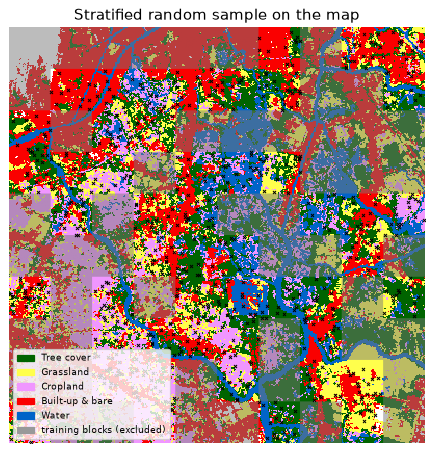

In [11]:
def draw_stratified_sample(n_per_class, rng):
    rows, cols = [], []
    for k in range(K):
        r, c = np.nonzero(population & (map_idx == k))
        pick = rng.choice(len(r), size=min(n_per_class[k], len(r)), replace=False)
        rows.append(r[pick]); cols.append(c[pick])
    return np.concatenate(rows), np.concatenate(cols)

s_rows, s_cols = draw_stratified_sample(n_i, rng)
s_map, s_ref, s_pur = map_idx[s_rows, s_cols], ref_idx[s_rows, s_cols], purity[s_rows, s_cols]
has_ref = s_ref >= 0
print(f"{len(s_rows)} sample pixels, {np.sum(~has_ref)} without a reference label (dropped)")
s_map, s_ref, s_pur = s_map[has_ref], s_ref[has_ref], s_pur[has_ref]

fig, ax = plt.subplots(figsize=(6, 6))
show(ax, map_idx, "Stratified random sample on the map")
ax.imshow(np.where(is_train_area, 0.6, np.nan), cmap="Greys", vmin=0, vmax=1, alpha=0.5)
ax.scatter(s_cols[has_ref], s_rows[has_ref], s=6, c="k", marker="x", linewidths=0.8)
ax.legend(handles=legend + [Patch(color="0.6", label="training blocks (excluded)")], loc="lower left", fontsize=7)
plt.show()

### 5.3 Analysis: area-weighted error matrix, accuracy and area with 95 % CIs

Each stratum was sampled at a different rate, so every sample count $n_{ij}$ is converted to an **estimated area
proportion** $\hat p_{ij} = W_i \, n_{ij} / n_{i+}$. From this matrix (Olofsson et al. 2014, Eqs. 2–11):

- $\hat O = \sum_j \hat p_{jj}$, $\;\hat U_i = \hat p_{ii}/\hat p_{i+}$, $\;\hat P_j = \hat p_{jj}/\hat p_{+j}$
- error-adjusted area of class $j$: $\hat A_j = A_{\text{total}}\,\hat p_{+j}$, with
  $S(\hat p_{+j}) = \sqrt{\sum_i \frac{W_i\,\hat p_{ij} - \hat p_{ij}^2}{n_{i+} - 1}}$
- 95 % confidence interval: estimate ± 1.96 × standard error.

In [12]:
def olofsson(map_lab, ref_lab, N_i, K):
    # Stratified estimators of Olofsson et al. (2014). Strata = map classes. Returns a dict of results.
    n_ij = np.zeros((K, K))
    for m_, r_ in zip(map_lab, ref_lab):
        n_ij[m_, r_] += 1
    n_i = n_ij.sum(1)
    W = N_i / N_i.sum()
    p_ij = W[:, None] * n_ij / n_i[:, None]
    p_col = p_ij.sum(0)
    OA = np.trace(p_ij)
    UA = np.diag(n_ij) / n_i
    PA = np.diag(p_ij) / p_col
    se_OA = np.sqrt(np.sum(W ** 2 * UA * (1 - UA) / (n_i - 1)))
    se_UA = np.sqrt(UA * (1 - UA) / (n_i - 1))
    # producer's accuracy SE, Olofsson et al. (2014) Eq. 7 (with estimated class totals N_hat_j)
    N_hat_j = (N_i[:, None] * n_ij / n_i[:, None]).sum(0)
    se_PA = np.zeros(K)
    for j in range(K):
        term1 = N_i[j] ** 2 * (1 - PA[j]) ** 2 * UA[j] * (1 - UA[j]) / (n_i[j] - 1)
        others = [i for i in range(K) if i != j]
        term2 = PA[j] ** 2 * sum(N_i[i] ** 2 * n_ij[i, j] / n_i[i] * (1 - n_ij[i, j] / n_i[i]) / (n_i[i] - 1) for i in others)
        se_PA[j] = np.sqrt((term1 + term2) / N_hat_j[j] ** 2)
    se_p_col = np.sqrt(np.sum((W[:, None] * p_ij - p_ij ** 2) / (n_i[:, None] - 1), axis=0))
    return dict(n_ij=n_ij, p_ij=p_ij, OA=OA, se_OA=se_OA, UA=UA, se_UA=se_UA, PA=PA, se_PA=se_PA,
                p_col=p_col, se_p_col=se_p_col)

res = olofsson(s_map, s_ref, N_i, K)
A_total_ha = N_i.sum() * PIXEL_HA
tab = pd.DataFrame({
    "UA ± 95% CI": [f"{u:.3f} ± {1.96 * s:.3f}" for u, s in zip(res["UA"], res["se_UA"])],
    "PA ± 95% CI": [f"{p:.3f} ± {1.96 * s:.3f}" for p, s in zip(res["PA"], res["se_PA"])],
    "mapped area (ha)": (N_i * PIXEL_HA).round(0),
    "error-adjusted area (ha)": (res["p_col"] * A_total_ha).round(0),
    "± 95% CI (ha)": (1.96 * res["se_p_col"] * A_total_ha).round(0),
}, index=NAMES)
display(tab)
print(f"Overall accuracy (area-weighted) = {res['OA']:.3f} ± {1.96 * res['se_OA']:.3f} (95% CI)")

,UA ± 95% CI,PA ± 95% CI,mapped area (ha),error-adjusted area (ha),± 95% CI (ha)
Tree cover,0.687 ± 0.068,0.562 ± 0.050,1897.0,2320.0,223.0
Grassland,0.394 ± 0.092,0.466 ± 0.087,1150.0,974.0,173.0
Cropland,0.407 ± 0.087,0.424 ± 0.075,1306.0,1250.0,195.0
Built-up & bare,0.737 ± 0.065,0.777 ± 0.055,1900.0,1804.0,173.0
Water,0.632 ± 0.102,0.705 ± 0.089,921.0,826.0,135.0


Overall accuracy (area-weighted) = 0.595 ± 0.035 (95% CI)


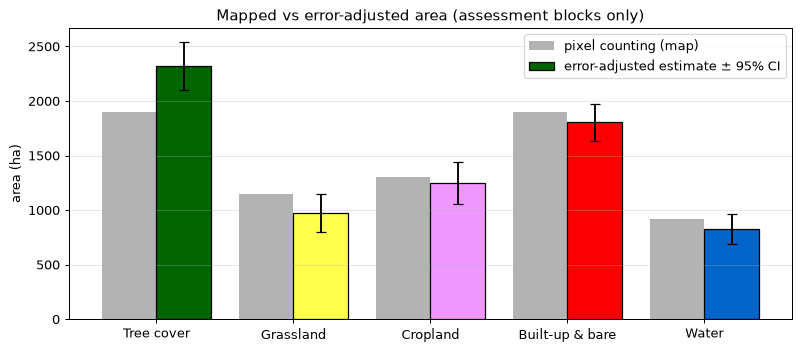

Sample agreement by WorldCover purity (how mixed the 30 m pixel is):
purity 1–5    0.337
purity 6–8    0.462
purity 9–9    0.736


In [13]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(K)
ax.bar(x - 0.2, N_i * PIXEL_HA, 0.4, label="pixel counting (map)", color="0.7")
ax.bar(x + 0.2, res["p_col"] * A_total_ha, 0.4, yerr=1.96 * res["se_p_col"] * A_total_ha, capsize=4,
       label="error-adjusted estimate ± 95% CI", color=COLORS, edgecolor="k")
ax.set_xticks(x); ax.set_xticklabels(NAMES)
ax.set(ylabel="area (ha)", title="Mapped vs error-adjusted area (assessment blocks only)")
ax.legend(); ax.grid(axis="y", alpha=0.3); plt.tight_layout(); plt.show()

by_purity = pd.Series({f"purity {lo}–{hi}": np.mean(s_map[(s_pur >= lo) & (s_pur <= hi)] == s_ref[(s_pur >= lo) & (s_pur <= hi)])
                       for lo, hi in ((1, 5), (6, 8), (9, 9))})
print("Sample agreement by WorldCover purity (how mixed the 30 m pixel is):")
print(by_purity.round(3).to_string())

Where the grey and coloured bars differ by more than the error bar, **pixel counting is biased**: the map
over- or under-estimates that class. Also note how much lower the agreement is for *mixed* pixels than for pure
pixels — which is why the pure-pixel test set in Section 3 was optimistic.

### 5.4 Do the confidence intervals work? A simulation

Because WorldCover covers every pixel, we can compute the *population* agreement exactly and check whether repeated
samples give confidence intervals that contain it about 95 % of the time. We also compare with a **simple random
sample** of the same size.

In [14]:
pop_rows, pop_cols = np.nonzero(population & (ref_idx >= 0))
true_OA = np.mean(map_idx[pop_rows, pop_cols] == ref_idx[pop_rows, pop_cols])
true_UA = np.array([np.mean(ref_idx[pop_rows, pop_cols][map_idx[pop_rows, pop_cols] == k] == k) for k in range(K)])

sims = {"stratified": [], "simple random": []}
for rep in range(300):
    r_, c_ = draw_stratified_sample(n_i, rng)
    keep = ref_idx[r_, c_] >= 0
    out = olofsson(map_idx[r_, c_][keep], ref_idx[r_, c_][keep], N_i, K)
    sims["stratified"].append((out["OA"], out["se_OA"], out["UA"][np.argmin(W_i)], out["se_UA"][np.argmin(W_i)]))
    pick = rng.choice(len(pop_rows), size=n_i.sum(), replace=False)
    m_, r2 = map_idx[pop_rows[pick], pop_cols[pick]], ref_idx[pop_rows[pick], pop_cols[pick]]
    oa, rare = np.mean(m_ == r2), m_ == np.argmin(W_i)
    ua = np.mean(r2[rare] == np.argmin(W_i)) if rare.sum() > 1 else np.nan
    sims["simple random"].append((oa, np.sqrt(oa * (1 - oa) / (len(m_) - 1)), ua,
                                  np.sqrt(ua * (1 - ua) / max(rare.sum() - 1, 1))))

rare_name = NAMES[np.argmin(W_i)]
rows_out = {}
for name, v in sims.items():
    v = np.array(v, dtype=float)
    cover = np.mean(np.abs(v[:, 0] - true_OA) <= 1.96 * v[:, 1])
    rows_out[name] = {"mean OA estimate": v[:, 0].mean(), "SD of OA estimates": v[:, 0].std(),
                      "95% CI coverage (OA)": cover,
                      f"SD of UA({rare_name}) estimates": np.nanstd(v[:, 2])}
display(pd.DataFrame(rows_out).T.round(4))
print(f"population agreement: OA = {true_OA:.4f}, UA({rare_name}) = {true_UA[np.argmin(W_i)]:.4f}")

,mean OA estimate,SD of OA estimates,95% CI coverage (OA),SD of UA(Water) estimates
stratified,0.6363,0.0185,0.9533,0.0492
simple random,0.6379,0.0190,0.9433,0.0515


population agreement: OA = 0.6378, UA(Water) = 0.6789


Both designs are unbiased for OA and their 95 % intervals cover the population value about 95 % of the time.
The benefit of stratification shows up for the **rarest map class**: with a guaranteed minimum sample, its user's
accuracy is estimated far more precisely than with a simple random sample of the same total size.

## 6. Continuous products: agreement metrics

Many projects produce **continuous** variables — an index, a chlorophyll or water-quality proxy, a burn-severity value.
Their validation uses a different toolbox:

| Metric | Formula | Meaning |
|---|---|---|
| Bias (mean error) | $\frac1n\sum (\hat y - y)$ | systematic over/under-estimation |
| MAE | $\frac1n\sum \lvert \hat y - y\rvert$ | typical error size |
| RMSE | $\sqrt{\frac1n\sum (\hat y - y)^2}$ | error size, penalises large errors |
| R² (1:1) | $1 - \frac{\sum (\hat y - y)^2}{\sum (y - \bar y)^2}$ | fraction of variance explained *on the 1:1 line* |
| Slope / intercept | OLS fit $\hat y = a + b y$ | scale and offset errors |
| Bland–Altman | difference vs mean, bias ± 1.96 SD | whether disagreement depends on the magnitude (Bland & Altman 1986) |

Here we compare **Tanager NDVI** (narrow 665 / 860 nm bands) with **Sentinel-2 NDVI simulated from the same Tanager
spectra** (Gaussian response functions of B04 and B08). This is a *cross-sensor consistency* check — it shows how much
of an index depends on band definitions. True *accuracy* of a biophysical product needs in-situ measurements taken at
the same time and representative of the 30 m pixel.

In [15]:
def agreement(y_ref, y_est):
    y_ref, y_est = np.asarray(y_ref, float), np.asarray(y_est, float)
    d = y_est - y_ref
    slope, intercept = np.polyfit(y_ref, y_est, 1)
    return {"n": len(d), "bias": d.mean(), "MAE": np.abs(d).mean(), "RMSE": np.sqrt(np.mean(d ** 2)),
            "R2 (1:1)": 1 - np.sum(d ** 2) / np.sum((y_ref - y_ref.mean()) ** 2),
            "r2 (Pearson)": np.corrcoef(y_ref, y_est)[0, 1] ** 2, "slope": slope, "intercept": intercept}

px = pix[rng.choice(len(pix), size=min(20000, len(pix)), replace=False)]      # 20 000 valid spectra
ndvi_tan = hu.nd(px[:, hu.band_index(wl, 860)], px[:, hu.band_index(wl, 665)])
s2 = hu.resample_to_sensor(wl, px, [hu.SENTINEL2_BANDS[b][0] for b in ("B04", "B05", "B08", "B8A")],
                           [hu.SENTINEL2_BANDS[b][1] for b in ("B04", "B05", "B08", "B8A")])
ndvi_s2 = hu.nd(s2[:, 2], s2[:, 0])
ndre_tan = hu.nd(px[:, hu.band_index(wl, 865)], px[:, hu.band_index(wl, 705)])
ndre_s2 = hu.nd(s2[:, 3], s2[:, 1])

display(pd.DataFrame({"NDVI: S2-simulated vs Tanager": agreement(ndvi_tan, ndvi_s2),
                      "NDRE: S2-simulated vs Tanager": agreement(ndre_tan, ndre_s2)}).T.round(4))

,n,bias,MAE,RMSE,R2 (1:1),r2 (Pearson),slope,intercept
NDVI: S2-simulated vs Tanager,20000.0,-0.0285,0.0287,0.0296,0.9731,0.9986,0.9718,-0.0170
NDRE: S2-simulated vs Tanager,20000.0,0.0102,0.0103,0.0114,0.9937,0.9992,1.0214,0.0043


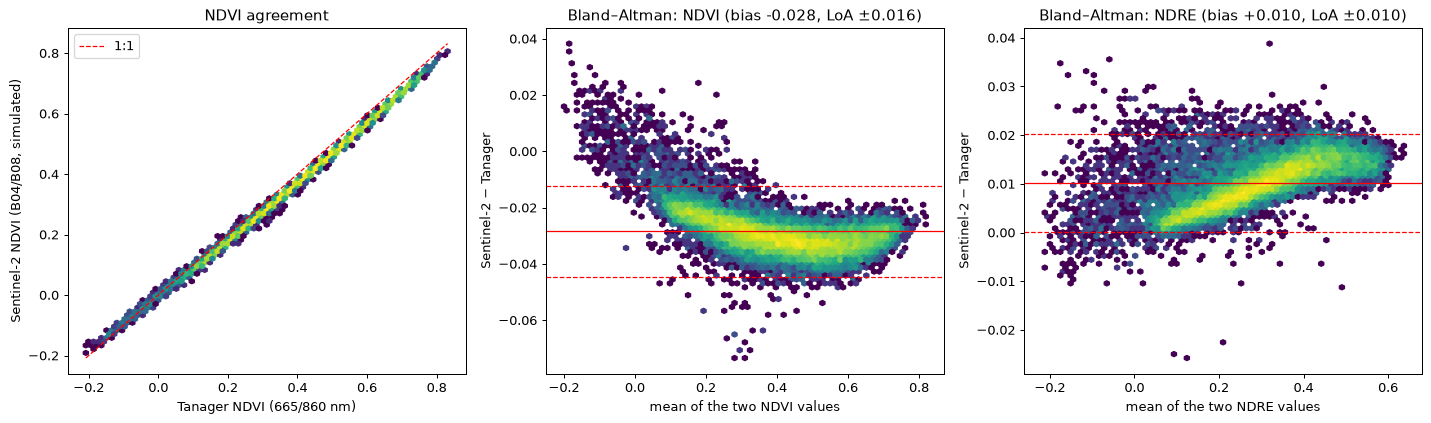

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
axes[0].hexbin(ndvi_tan, ndvi_s2, gridsize=70, bins="log", cmap="viridis", mincnt=1)
lim = [min(ndvi_tan.min(), ndvi_s2.min()), max(ndvi_tan.max(), ndvi_s2.max())]
axes[0].plot(lim, lim, "r--", lw=1, label="1:1")
axes[0].set(xlabel="Tanager NDVI (665/860 nm)", ylabel="Sentinel-2 NDVI (B04/B08, simulated)", title="NDVI agreement")
axes[0].legend()
for ax, (x, y, name) in zip(axes[1:], ((ndvi_tan, ndvi_s2, "NDVI"), (ndre_tan, ndre_s2, "NDRE"))):
    mean, diff = (x + y) / 2, y - x
    b, sd = diff.mean(), diff.std()
    ax.hexbin(mean, diff, gridsize=70, bins="log", cmap="viridis", mincnt=1)
    for v, ls in ((b, "-"), (b + 1.96 * sd, "--"), (b - 1.96 * sd, "--")):
        ax.axhline(v, color="r", ls=ls, lw=1)
    ax.set(xlabel=f"mean of the two {name} values", ylabel="Sentinel-2 − Tanager",
           title=f"Bland–Altman: {name} (bias {b:+.3f}, LoA ±{1.96 * sd:.3f})")
plt.tight_layout(); plt.show()

NDVI agrees closely — the broad Sentinel-2 bands and Tanager's narrow bands sample the same smooth parts of the
spectrum. The red-edge index shows larger, **magnitude-dependent** differences in the Bland–Altman plot: the red
edge is steep, so band position and width matter. Never mix index values from different sensors without such a
consistency check (or a harmonisation, notebook 30).

## 7. Optional: cross-date consistency on stable targets (Malibu)

Two Tanager scenes of the Santa Monica Mountains, 39 days apart, overlap. On **pseudo-invariant features** — built-up
surfaces that did not burn or change — surface reflectance should be the same on both dates. The residual differences
measure the *radiometric consistency* of the product (atmospheric correction, BRDF / view-angle effects,
co-registration), which bounds the smallest change you can detect in change-detection projects (notebook 30).

The second scene (`20250123_185518_92_4001`, ~1.3 GB) is not part of the theme notebooks. Set
`DOWNLOAD_SECOND_SCENE = True` to download it, otherwise this section is skipped if it is not available locally.

In [17]:
DOWNLOAD_SECOND_SCENE = False
ID_A, ID_B = "20241215_185916_33_4001", "20250123_185518_92_4001"

if hu.find_local(ID_B, allow_subset=False) is None and not DOWNLOAD_SECOND_SCENE:
    print(f"{ID_B} not found locally — section skipped (set DOWNLOAD_SECOND_SCENE = True to fetch it).")
    run_cross_date = False
else:
    run_cross_date = True
    sa, sb = hu.get_scene(ID_A), hu.get_scene(ID_B)
    assert sa.crs == sb.crs and sa.res_x == sb.res_x
    # both grids share the UTM zone and 30 m pixels: find the integer offset of scene B relative to scene A
    d_row = int(round((sb.ul_y - sa.ul_y) / sa.res_y))      # row in B = row in A + d_row
    d_col = int(round((sa.ul_x - sb.ul_x) / sa.res_x))      # col in B = col in A + d_col
    r0, r1 = max(0, -d_row), min(sa.shape[1], sb.shape[1] - d_row)
    c0, c1 = max(0, -d_col), min(sa.shape[2], sb.shape[2] - d_col)
    win_a, win_b = (r0, r1, c0, c1), (r0 + d_row, r1 + d_row, c0 + d_col, c1 + d_col)
    print(f"offset rows {d_row:+d}, cols {d_col:+d}; overlap window in A = {win_a} ({r1 - r0}×{c1 - c0} px)")

offset rows +295, cols -114; overlap window in A = (0, 713, 114, 791) (713×677 px)


best NIR correlation 0.548 at shift (rows +0, cols -1) → consider shifting one image
1011 pseudo-invariant pixels


,n,bias,RMSE,relative RMSE %,r2 (Pearson)
480 nm,1011.0,0.0283,0.0324,31.6396,0.6462
560 nm,1011.0,0.0250,0.0325,26.4563,0.5822
665 nm,1011.0,0.0247,0.0336,26.9937,0.5922
705 nm,1011.0,0.0271,0.0374,26.0027,0.4818
860 nm,1011.0,0.0365,0.0492,25.1765,0.4745
1250 nm,1011.0,0.0417,0.0585,28.1058,0.4099
1650 nm,1011.0,0.0403,0.0615,31.8815,0.3180
2200 nm,1011.0,0.0343,0.0560,36.1907,0.2979


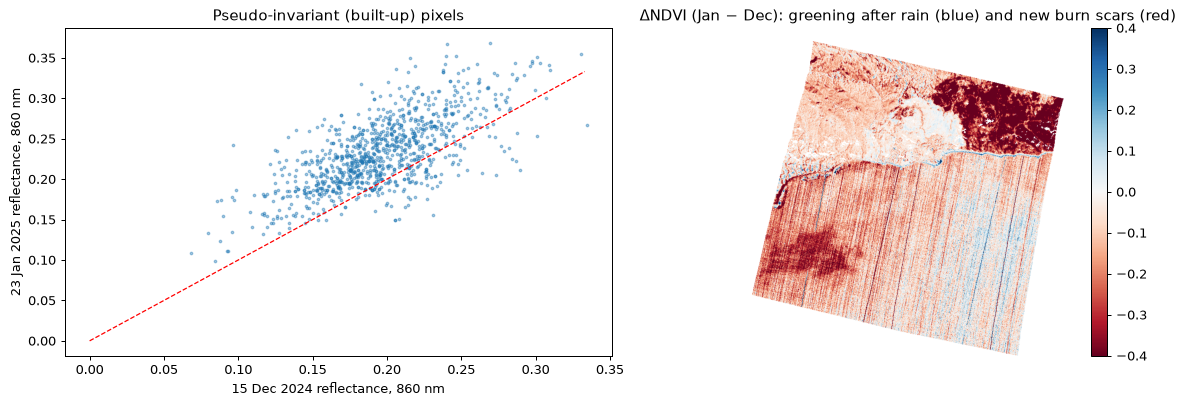

In [18]:
if run_cross_date:
    WLS = [480, 560, 665, 705, 860, 1250, 1650, 2200]
    bands_a = np.stack([sa.read_band(w, win_a) for w in WLS])
    bands_b = np.stack([sb.read_band(w, win_b) for w in WLS])

    # 1. co-registration check: correlation of the NIR band for small integer shifts
    nir_a, nir_b = np.nan_to_num(bands_a[4]), np.nan_to_num(bands_b[4])
    best = max(((np.corrcoef(nir_a[5:-5, 5:-5].ravel(),
                             np.roll(np.roll(nir_b, dy, 0), dx, 1)[5:-5, 5:-5].ravel())[0, 1], dy, dx)
                for dy in range(-2, 3) for dx in range(-2, 3)))
    print(f"best NIR correlation {best[0]:.3f} at shift (rows {best[1]:+d}, cols {best[2]:+d}) → "
          f"{'grids are aligned' if best[1:] == (0, 0) else 'consider shifting one image'}")

    # 2. pseudo-invariant features: pure built-up pixels, valid on both dates, with stable NDVI
    wc_a, pur_a = hu.load_labels(ID_A, win_a)
    ndvi_a, ndvi_b = hu.nd(bands_a[4], bands_a[2]), hu.nd(bands_b[4], bands_b[2])
    pif = (wc_a == 50) & (pur_a >= 8) & np.all(np.isfinite(bands_a), 0) & np.all(np.isfinite(bands_b), 0) \
          & (np.abs(ndvi_b - ndvi_a) < 0.05)
    print(f"{pif.sum()} pseudo-invariant pixels")
    cons = pd.DataFrame({f"{w} nm": agreement(bands_a[i][pif], bands_b[i][pif]) for i, w in enumerate(WLS)}).T
    cons["relative RMSE %"] = 100 * cons["RMSE"] / np.array([np.mean(bands_a[i][pif]) for i in range(len(WLS))])
    display(cons[["n", "bias", "RMSE", "relative RMSE %", "r2 (Pearson)"]].round(4))

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
    axes[0].scatter(bands_a[4][pif], bands_b[4][pif], s=4, alpha=0.4)
    lim = [0, np.nanpercentile(bands_a[4][pif], 99.5) * 1.1]
    axes[0].plot(lim, lim, "r--", lw=1)
    axes[0].set(xlabel="15 Dec 2024 reflectance, 860 nm", ylabel="23 Jan 2025 reflectance, 860 nm",
                title="Pseudo-invariant (built-up) pixels")
    im = axes[1].imshow(ndvi_b - ndvi_a, cmap="RdBu", vmin=-0.4, vmax=0.4)
    axes[1].set_title("ΔNDVI (Jan − Dec): greening after rain (blue) and new burn scars (red)"); axes[1].axis("off")
    plt.colorbar(im, ax=axes[1], fraction=0.04)
    plt.tight_layout(); plt.show()

If the relative RMSE on stable targets is a few percent, a reflectance change smaller than that cannot be told
apart from radiometric noise — a useful, *measured* detection threshold for change-detection projects.

## 8. What to report in your project

The hackathon **Validity** criterion asks for *scientific and technical rigor*, and every theme notebook ends with
"How good is your model, really?". Use this checklist:

| Product type | Reference data | Sampling / splitting | Report | Avoid |
|---|---|---|---|---|
| **Class map** (land cover, crop type, burn severity) | field or VHR photo-interpretation, independent of training | stratified random sample by map class; spatial CV for model selection | error matrix (sample counts **and** area proportions), OA, UA, PA with 95 % CI, F1 per class, error-adjusted areas ± CI | kappa alone; reusing training pixels; random-pixel CV; pure-pixel-only tests |
| **Detection** (plumes, specific materials, targets) | confirmed targets **and** many confirmed negatives | include negatives from several scenes | precision, recall, F1, precision–recall curve / average precision, false alarms per km² | accuracy on very imbalanced data; tuning the threshold on the test set |
| **Segmentation / objects** | digitised outlines | spatially held-out tiles | IoU per class, boundary F-score | pixel accuracy dominated by background |
| **Continuous variable** (chlorophyll, turbidity, moisture) | in-situ or higher-quality product, same date, representative of 30 m | independent sites; spatial CV | n, bias, MAE, RMSE, R² (1:1), slope/intercept, Bland–Altman | correlation only; time or scale mismatch |
| **Change** (burn scars, urban growth, floods) | change / no-change reference pairs | stratify by change class — change is rare! | UA / PA of change, area of change ± CI, detectability threshold from stable targets | assessing each date separately only |

Always state: the reference data source and date, the response design, the sample size and allocation, the error-matrix
orientation, the split or block size, and the uncertainty (confidence intervals) of every number.

## ✏️ Your turn

**1. Sample size.** Lower `TARGET_SE` to 0.01 and change the conjectured user's accuracies. How does the required
sample size change? Why is it so sensitive to `TARGET_SE`?

<details><summary>Hint</summary>

$n$ scales with $1/S(\hat O)^2$ — halving the standard error needs four times the samples.
</details>

<details><summary>Solution</summary>

```python
for se in (0.02, 0.015, 0.01):
    print(se, int(np.ceil((np.sum(W_i * np.sqrt(U_guess * (1 - U_guess))) / se) ** 2)))
```
</details>

**2. Allocation.** Redo Section 5 with **equal allocation** (the same number of samples per class, same total).
Which confidence intervals get narrower, which get wider?

<details><summary>Solution</summary>

```python
n_eq = np.full(K, n_i.sum() // K)
r_, c_ = draw_stratified_sample(n_eq, rng)
keep = ref_idx[r_, c_] >= 0
res_eq = olofsson(map_idx[r_, c_][keep], ref_idx[r_, c_][keep], N_i, K)
print("OA", res_eq["OA"].round(3), "±", (1.96 * res_eq["se_OA"]).round(3))
print("UA CI half-widths", (1.96 * res_eq["se_UA"]).round(3), "vs", (1.96 * res["se_UA"]).round(3))
# Rare classes get narrower UA intervals; the OA interval usually widens a little.
```
</details>

**3. Quantity vs allocation.** Compute $Q$ and $A$ for the three models of notebook 20 (or your own project map).
Is your error mainly about *how much* or about *where*?

**4. A buffered spatial CV.** In Section 4, remove from each training fold all pixels within 5 pixels of the test
fold before fitting. How much does accuracy drop further for small blocks?

<details><summary>Hint</summary>

Build a boolean image of the test-fold pixels, dilate it with `scipy.ndimage.binary_dilation(mask, iterations=5)`,
and drop training pixels that fall inside the dilated mask.
</details>

**5. Another sensor.** Repeat Section 6 with Landsat 8 bands (`hu.LANDSAT8_BANDS`: B4 and B5). Is the NDVI bias
larger or smaller than for Sentinel-2? Why?

## Key takeaways

- A credible accuracy statement needs **independent reference data**, a **probability sampling design** and an
  **analysis that matches the design** — and it always comes with confidence intervals.
- Report the full **error matrix**, user's and producer's accuracies and F1; prefer quantity/allocation disagreement over kappa.
- **Random CV is optimistic** for maps. Use spatial blocks at least as large as the autocorrelation range.
- Use the **stratified estimators** (Olofsson et al. 2014) to report **error-adjusted areas** — pixel counting is biased.
- For continuous products, report bias, MAE, RMSE, R² and a Bland–Altman plot, and be explicit whether you measure
  *accuracy* (against in-situ truth) or *consistency* (against another product).

**References:** Olofsson et al. (2014) *Remote Sensing of Environment* 148:42–57 · Stehman & Foody (2019) *RSE* 231:111199 ·
Pontius & Millones (2011) *Int. J. Remote Sensing* 32:4407–4429 · Foody (2020) *RSE* 239:111630 · Congalton & Green (2019)
*Assessing the Accuracy of Remotely Sensed Data* · Roberts et al. (2017) *Ecography* 40:913–929 · Ploton et al. (2020)
*Nature Communications* 11:4540 · Meyer & Pebesma (2022) *Nature Communications* 13:2208 · Cochran (1977) *Sampling Techniques* ·
Bland & Altman (1986) *The Lancet* 327:307–310.

---
> 📖 Data: Tanager — CC-BY-4.0 © Planet Labs PBC · ESA WorldCover 2021 v200 — CC-BY 4.0

In [19]:
print(f"Notebook runtime: {(time.time() - T_START) / 60:.1f} min")

Notebook runtime: 0.4 min
